# EchoPath — Jetson Implementation

Copy of `midas_small/EchoPath_Pipeline_MiDaS_v2_with_TTS (2).ipynb` with the three
alert-policy gaps fixed. Detection, depth and fusion are **unchanged**.

### What changed

| Gap | Was | Now |
|---|---|---|
| **1 · No priority** | `queue.Queue()` unbounded FIFO — a `close` alert queued behind a playing `medium` one | Depth-1 priority slot; a closer alert **replaces** a waiting one; stale alerts are dropped |
| **2 · Four cooldowns** | `MIN_ALERT_GAP=1.5`, `REPEAT_COOLDOWN=5.0` (cell 9), `MIN_GAP_SECONDS=2.0` (cell 11), paper says 2.5 | One `AlertPolicy`, one set of constants, used by cells 7, 10 and 11 alike |
| **3 · Backlog** | Alerts emitted every 1.5 s but phrases take 1.3–3.2 s → queue grew without bound, audio drifted seconds behind reality | `MIN_GAP_S` ≥ longest phrase, and the depth-1 queue makes overrun *drop* instead of *lag* |

Also fixed: the repeat cooldown keyed on the **phrase string**, so a chair drifting
`medium`→`close` produced a different string and bypassed it entirely. It now keys on
`(label, direction)`.

Natural phrasing is retained — `"chair close on your left"`, not `"chair close left"`.
That costs about a second per alert, so `MIN_GAP_S` is set accordingly.

---

### Dependencies

**This notebook (workstation)** — `torch`, `ultralytics`, `opencv-python`, `timm`,
`pyttsx3`, `imageio-ffmpeg`, `matplotlib`.

**Jetson Nano (JetPack 4.6 / Python 3.6)** — none of the above will install.
`ultralytics` needs Python ≥3.8; `torch` 2.x needs ≥3.8. The device runs:
`tensorrt` + `cv2` + `numpy` from JetPack, plus `pycuda`. Detection and depth become
TensorRT `.plan` engines built on the board from ONNX.

Cells marked **LIFTABLE** below are stdlib-only and Python 3.6 clean, so they move to
the device unchanged. That is deliberate: it keeps the workstation and the device
running identical alert logic.

## Cell 1 — Environment probe  · **LIFTABLE**

Sets `BACKEND` once. Everything downstream branches on this and never on
`torch.cuda.is_available()`, which is what lets the same notebook run on the
workstation and on the Jetson.

| | Workstation | Jetson Nano |
|---|---|---|
| `BACKEND` | `torch` | `tensorrt` |
| Detector | Ultralytics `best.pt` | TensorRT `.plan` (FP16) |
| Depth | MiDaS via torch | TensorRT `.plan` (FP16) |

In [13]:
import os, sys, platform

# JetPack writes this file; it is the reliable way to know we are on a Tegra board.
IS_JETSON = os.path.exists('/etc/nv_tegra_release')
BACKEND   = 'tensorrt' if IS_JETSON else 'torch'

print('platform : %s %s' % (platform.system(), platform.machine()))
print('python   : %s' % sys.version.split()[0])
print('jetson   : %s' % IS_JETSON)
print('BACKEND  : %s' % BACKEND)

if BACKEND == 'torch':
    import torch
    print('torch    : %s   cuda=%s' % (torch.__version__, torch.cuda.is_available()))
    if torch.cuda.is_available():
        print('gpu      : %s' % torch.cuda.get_device_name(0))
        print('vram     : %.1f GB' % (torch.cuda.get_device_properties(0).total_memory / 1e9))
    else:
        print('WARNING: no GPU - this will be very slow')
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
else:
    # JetPack 4.6 ships tensorrt and cv2 into the system python; pycuda is the only pip
    # install needed. torch and ultralytics CANNOT be installed here (Python 3.6).
    import tensorrt as trt
    import pycuda.driver as cuda
    import pycuda.autoinit          # noqa: F401  - initialises the CUDA context
    import cv2 as _cv2
    print('tensorrt : %s' % trt.__version__)
    print('opencv   : %s   GStreamer: %s'
          % (_cv2.__version__,
             'YES' if 'GStreamer:                   YES' in _cv2.getBuildInformation()
             else 'NO  <-- CSI camera will not work'))
    device = 'cuda'

platform : Windows AMD64
python   : 3.11.15
jetson   : False
BACKEND  : torch
torch    : 2.4.1+cu118   cuda=True
gpu      : NVIDIA RTX 4500 Ada Generation
vram     : 25.8 GB


## Cell 2 — Paths and alert-policy constants  · **LIFTABLE (constants)**

One place for every timing number. Previously these were spread across cells 9 and 11
and disagreed with each other and with the paper.

In [14]:
import os

# ── EDIT THESE BASE PATHS ─────────────────────────────────────────────────────
YOLO_WEIGHTS = r"E:\EchoPath\runs\detect\runs\echopath\v3\weights\best.pt"
VIDEO_DIR    = r"E:\EchoPath\Video_Data"   # drop any video here, it gets picked up automatically
OUTPUT_DIR   = r"E:\EchoPath\Jetson_Implementation\output"
# ─────────────────────────────────────────────────────────────────────────────

SUPPORTED_EXTS = {'.mp4', '.avi', '.mov', '.mkv', '.MOV', '.MP4'}

os.makedirs(OUTPUT_DIR, exist_ok=True)
# On the device there are no .pt weights and no video folder - only engines and a
# camera, so these checks are workstation-only.
if BACKEND == 'torch':
    assert os.path.exists(YOLO_WEIGHTS), f'YOLO weights not found: {YOLO_WEIGHTS}'
    assert os.path.exists(VIDEO_DIR),    f'Video folder not found: {VIDEO_DIR}'

# Auto-discover all videos in the folder
VIDEO_JOBS = [] if not os.path.isdir(VIDEO_DIR) else [
    (
        os.path.join(VIDEO_DIR, f),
        os.path.join(OUTPUT_DIR, f"echopath_{f}")
    )
    for f in sorted(os.listdir(VIDEO_DIR))
    if os.path.splitext(f)[1] in SUPPORTED_EXTS
]

if BACKEND == 'torch':
    assert len(VIDEO_JOBS) > 0, f'No videos found in {VIDEO_DIR}. Supported: {SUPPORTED_EXTS}'

print(f'Weights : {YOLO_WEIGHTS}')
print(f'Found {len(VIDEO_JOBS)} video(s) in {VIDEO_DIR}:')
for inp, out in VIDEO_JOBS:
    print(f'  {os.path.basename(inp)}  →  {os.path.basename(out)}')

# TIP: to test on just ONE video first, uncomment the next line:
# VIDEO_JOBS = VIDEO_JOBS[:1]


# ── Alert policy — the single source of truth ────────────────────────────────
# Rendered phrases run 1.3-3.2 s at SPEECH_RATE. Emitting faster than that makes the
# audio queue grow without bound: the user ends up hearing where they WERE, not where
# they are. So the floor between alerts must exceed the longest phrase.
SPEECH_RATE      = 170     # words per minute
SPEECH_VOLUME    = 1.0
# Measured from the rendered vocabulary: phrases run 1.29-3.18 s (median 2.36 s).
# The floor must clear the LONGEST of them, or that phrase gets cut off by the next
# alert. Cell 9 re-measures the actual WAVs on every run and warns if this drifts.
ALERT_COOLDOWN_S = 3.5     # same (label, direction) may not repeat within this
MIN_GAP_S        = 3.5     # between ANY two alerts; > longest phrase (3.18 s)
STALE_S          = 1.5     # drop a queued alert older than this instead of speaking it
ALERT_ZONES      = ('close', 'medium')     # 'far' is never announced

# ── Audio output ─────────────────────────────────────────────────────────────
# The alert grammar is a CLOSED SET, so every sentence the device can ever say is
# rendered once here and simply played back on the board. Making a voice costs real
# CPU; playing a file costs almost none, and the Jetson has four weak A57 cores that
# are already busy with detection.
VOCAB_DIR      = os.path.join(os.path.dirname(OUTPUT_DIR), 'assets', 'audio')
USE_VOCABULARY = True      # False -> synthesise live (slow, and cannot be interrupted)

# Which sound device to play through. The Eagle 101 has NO analog audio codec - sound
# exists only inside HDMI/DisplayPort - so a USB audio dongle is required. Without
# naming it here, ALSA picks its own default, which on a headless board is often HDMI:
# earphones plugged in, everything running, and complete silence with no error.
#   Find yours with:  aplay -l
#   then set e.g.     ALSA_DEVICE = 'plughw:2,0'
ALSA_DEVICE    = 'default'

if not os.path.isdir(VOCAB_DIR):
    os.makedirs(VOCAB_DIR)

print(f'\nAlert policy: cooldown {ALERT_COOLDOWN_S}s | min gap {MIN_GAP_S}s | '
      f'stale after {STALE_S}s')

# ── TensorRT engine paths (device only) ──────────────────────────────────────
# Engines are NOT portable across TensorRT version or GPU architecture, so they must
# be built ON the Jetson from the ONNX files:
#   /usr/src/tensorrt/bin/trtexec --onnx=onnx/yolov8n_640.onnx --fp16 --verbose \
#       --workspace=512 --saveEngine=engines/yolo_640_fp16.plan
#   /usr/src/tensorrt/bin/trtexec --onnx=onnx/midas_small_256.onnx --fp16 \
#       --workspace=512 --saveEngine=engines/midas_256_fp16.plan
# FP16, not INT8: the Nano's Maxwell GPU is compute capability 5.3 and lacks the DP4A
# instruction INT8 needs. trtexec --int8 warns and silently falls back.
ENGINE_DIR   = os.path.join(os.path.dirname(OUTPUT_DIR), 'engines')
YOLO_ENGINE  = os.path.join(ENGINE_DIR, 'yolo_640_fp16.plan')
DEPTH_ENGINE = os.path.join(ENGINE_DIR, 'midas_256_fp16.plan')
YOLO_IMGSZ   = 640          # keep 640: at 416 the letterbox loses up to 52% of
                            # detections on 1080x1920 portrait input
DEPTH_SIZE   = 256          # MiDaS Small native resolution

# ── CSI camera (device only) ─────────────────────────────────────────────────
CSI_SENSOR_ID, CSI_W, CSI_H, CSI_FPS, CSI_FLIP = 0, 1280, 720, 30, 0

# ── Class names — MUST match the engine's output channel count ───────────────
# The .plan file carries weights but NOT class names, so they have to be written out
# here. data.yaml declares nc=19; using the paper's 17 would shift every index above
# 10 and make wet_floor_sign report as monitor (which is silenced).
CLASS_NAMES = ['person', 'chair', 'door', 'stairs', 'slide', 'whiteboard',
               'notice_board', 'elevator', 'column', 'window', 'water_dispenser',
               'backpack', 'handbag', 'potted_plant', 'waste_bin',
               'fire_extinguisher', 'wet_floor_sign', 'table', 'monitor']

Weights : E:\EchoPath\runs\detect\runs\echopath\v3\weights\best.pt
Found 13 video(s) in E:\EchoPath\Video_Data:
  Classroom.MP4  →  echopath_Classroom.MP4
  Enterance.MP4  →  echopath_Enterance.MP4
  FDW.mp4  →  echopath_FDW.mp4
  Manthan.mp4  →  echopath_Manthan.mp4
  Persons.mp4  →  echopath_Persons.mp4
  Stairs.MP4  →  echopath_Stairs.MP4
  Water.mp4  →  echopath_Water.mp4
  acad_entry.mp4  →  echopath_acad_entry.mp4
  first_floor.mp4  →  echopath_first_floor.mp4
  lab.mp4  →  echopath_lab.mp4
  sign.mp4  →  echopath_sign.mp4
  trash_bin.mp4  →  echopath_trash_bin.mp4
  water1.mp4  →  echopath_water1.mp4

Alert policy: cooldown 3.5s | min gap 3.5s | stale after 1.5s


## Cell 3 — Load models (backend-aware)  · **LIFTABLE**

Two implementations behind one interface. The TensorRT side deliberately **mimics the
Ultralytics API** (`predict()`, `.boxes`, `.xyxy`, `.cls`, `.conf`, `.names`) so that
Cell 4 — your working fusion code — needs essentially no change.

**Workstation:** Ultralytics `best.pt` + MiDaS from `torch.hub`.

**Jetson:** two TensorRT engines. Post-processing (decode + NMS) is done in NumPy
because TensorRT 8.2's NMS plugin on JetPack 4.6 is unreliable.

> The TensorRT path is written but **has not been run against a real engine** — there is
> no board yet. Expect to debug binding names and output layout on first contact.

In [15]:
# ─── Cell 3: Load models ────────────────────────────────────────────────────
import numpy as np
import cv2

if BACKEND == 'torch':
    # ---------------------------------------------------------------- workstation
    from ultralytics import YOLO

    print(f'Using device: {device}')
    yolo_model = YOLO(YOLO_WEIGHTS)
    print('YOLO loaded')

    MIDAS_MODEL_TYPE = 'MiDaS_small'
    print(f'Loading MiDaS: {MIDAS_MODEL_TYPE} ...')
    midas = torch.hub.load('intel-isl/MiDaS', MIDAS_MODEL_TYPE, trust_repo=True)
    midas.to(device)
    midas.eval()
    midas_transforms = torch.hub.load('intel-isl/MiDaS', 'transforms', trust_repo=True)
    midas_transform = (midas_transforms.small_transform
                       if MIDAS_MODEL_TYPE == 'MiDaS_small'
                       else midas_transforms.dpt_transform)
    print('MiDaS loaded')

else:
    # ---------------------------------------------------------------- Jetson
    import tensorrt as trt
    import pycuda.driver as cuda

    class TRTEngine(object):
        """Minimal TensorRT 8.2 runner: static shapes, batch 1, pinned host buffers."""

        def __init__(self, plan_path):
            if not os.path.exists(plan_path):
                raise IOError('engine not found: %s\n'
                              'Build it on the device with trtexec (see Cell 2).'
                              % plan_path)
            logger = trt.Logger(trt.Logger.WARNING)
            with open(plan_path, 'rb') as f, trt.Runtime(logger) as rt:
                self.engine = rt.deserialize_cuda_engine(f.read())
            if self.engine is None:
                raise IOError('failed to deserialise %s - engines are not portable '
                              'across TensorRT version or GPU.' % plan_path)
            self.ctx = self.engine.create_execution_context()
            self.stream = cuda.Stream()
            self.bindings, self.host, self.dev, self.shapes = [], {}, {}, {}
            for i in range(self.engine.num_bindings):
                name = self.engine.get_binding_name(i)
                shape = tuple(self.engine.get_binding_shape(i))
                dtype = trt.nptype(self.engine.get_binding_dtype(i))
                h = cuda.pagelocked_empty(int(np.prod(shape)), dtype)
                d = cuda.mem_alloc(h.nbytes)
                self.bindings.append(int(d))
                self.host[name], self.dev[name], self.shapes[name] = h, d, shape
                if self.engine.binding_is_input(i):
                    self.in_name = name
                else:
                    self.out_name = name

        def __call__(self, x):
            np.copyto(self.host[self.in_name], x.ravel())
            cuda.memcpy_htod_async(self.dev[self.in_name],
                                   self.host[self.in_name], self.stream)
            self.ctx.execute_async_v2(self.bindings, self.stream.handle)
            cuda.memcpy_dtoh_async(self.host[self.out_name],
                                   self.dev[self.out_name], self.stream)
            self.stream.synchronize()
            return self.host[self.out_name].reshape(self.shapes[self.out_name])

    # -- shims so Cell 4 can keep using the Ultralytics attribute names -----------
    class _Arr(object):
        """Stands in for a torch tensor slice: supports .cpu().numpy() and indexing."""
        def __init__(self, a):
            self._a = a
        def cpu(self):
            return self
        def numpy(self):
            return self._a
        def __getitem__(self, i):
            return self._a[i]
        def __int__(self):
            return int(self._a)
        def __float__(self):
            return float(self._a)

    class _Box(object):
        def __init__(self, xyxy, cls_id, conf):
            self.xyxy = [_Arr(np.asarray(xyxy, dtype=np.float32))]
            self.cls  = [float(cls_id)]
            self.conf = [float(conf)]

    class _Result(object):
        def __init__(self, boxes):
            self.boxes = boxes

    def _letterbox(frame, size):
        h, w = frame.shape[:2]
        r = min(size / float(h), size / float(w))
        nh, nw = int(round(h * r)), int(round(w * r))
        dh, dw = (size - nh) // 2, (size - nw) // 2
        canvas = np.full((size, size, 3), 114, np.uint8)
        canvas[dh:dh + nh, dw:dw + nw] = cv2.resize(frame, (nw, nh))
        blob = cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        return np.ascontiguousarray(blob.transpose(2, 0, 1)[None]), r, dw, dh

    def _nms(boxes, scores, thr=0.45):
        x1, y1, x2, y2 = boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3]
        areas = (x2 - x1) * (y2 - y1)
        order = scores.argsort()[::-1]
        keep = []
        while order.size:
            i = order[0]
            keep.append(i)
            if order.size == 1:
                break
            xx1 = np.maximum(x1[i], x1[order[1:]]); yy1 = np.maximum(y1[i], y1[order[1:]])
            xx2 = np.minimum(x2[i], x2[order[1:]]); yy2 = np.minimum(y2[i], y2[order[1:]])
            inter = np.maximum(0, xx2 - xx1) * np.maximum(0, yy2 - yy1)
            iou = inter / (areas[i] + areas[order[1:]] - inter + 1e-9)
            order = order[1:][iou <= thr]
        return keep

    class TRTYolo(object):
        """Ultralytics-shaped wrapper around a YOLOv8 TensorRT engine."""

        def __init__(self, plan=None, imgsz=None, names=None):
            self.eng = TRTEngine(plan or YOLO_ENGINE)
            self.imgsz = imgsz or YOLO_IMGSZ
            self.names = {i: n for i, n in enumerate(names or CLASS_NAMES)}
            ch = self.eng.shapes[self.eng.out_name][1]        # (1, 4+nc, anchors)
            if ch - 4 != len(self.names):
                raise RuntimeError(
                    'engine has %d classes but CLASS_NAMES has %d. Indices would be '
                    'silently remapped - e.g. wet_floor_sign reported as monitor. '
                    'Fix CLASS_NAMES or re-export.' % (ch - 4, len(self.names)))
            print('YOLO engine loaded: %d classes, imgsz %d' % (ch - 4, self.imgsz))

        def predict(self, frame, conf=0.25, verbose=False, **kw):
            blob, r, dw, dh = _letterbox(frame, self.imgsz)
            p = np.squeeze(self.eng(blob))
            if p.shape[0] < p.shape[1]:
                p = p.T                                       # -> (anchors, 4+nc)
            xywh, cls = p[:, :4], p[:, 4:]
            sc, cid = cls.max(1), cls.argmax(1)
            m = sc >= conf
            if not m.any():
                return [_Result([])]
            xywh, sc, cid = xywh[m], sc[m], cid[m]
            xy, wh = xywh[:, :2], xywh[:, 2:]
            b = np.concatenate([xy - wh / 2, xy + wh / 2], 1)
            b[:, [0, 2]] = ((b[:, [0, 2]] - dw) / r).clip(0, frame.shape[1] - 1)
            b[:, [1, 3]] = ((b[:, [1, 3]] - dh) / r).clip(0, frame.shape[0] - 1)
            out = []
            for c in np.unique(cid):
                s = cid == c
                for i in _nms(b[s], sc[s]):
                    out.append(_Box(b[s][i], c, sc[s][i]))
            return [_Result(out)]

    class TRTDepth(object):
        """MiDaS Small engine. Preprocessing reimplemented in numpy - no torchvision."""

        MEAN = np.array([0.485, 0.456, 0.406], np.float32)
        STD  = np.array([0.229, 0.224, 0.225], np.float32)

        def __init__(self, plan=None, size=None):
            self.eng = TRTEngine(plan or DEPTH_ENGINE)
            self.size = size or DEPTH_SIZE
            print('MiDaS engine loaded: %dx%d' % (self.size, self.size))

        def __call__(self, frame_bgr):
            img = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (self.size, self.size), interpolation=cv2.INTER_CUBIC)
            img = (img.astype(np.float32) / 255.0 - self.MEAN) / self.STD
            d = self.eng(np.ascontiguousarray(img.transpose(2, 0, 1)[None])).squeeze()
            # Cell 4 expects a map at frame resolution.
            return cv2.resize(d, (frame_bgr.shape[1], frame_bgr.shape[0]),
                              interpolation=cv2.INTER_CUBIC)

    yolo_model  = TRTYolo()
    _trt_depth  = TRTDepth()
    print('TensorRT backend ready')

Using device: cuda
YOLO loaded
Loading MiDaS: MiDaS_small ...


Using cache found in C:\Users\AIDSHPCLAB30/.cache\torch\hub\intel-isl_MiDaS_master


Loading weights:  None


Using cache found in C:\Users\AIDSHPCLAB30/.cache\torch\hub\rwightman_gen-efficientnet-pytorch_master


MiDaS loaded


Using cache found in C:\Users\AIDSHPCLAB30/.cache\torch\hub\intel-isl_MiDaS_master


## Cell 4 — Core pipeline functions (MiDaS variant)

**Also defines `AlertPolicy`** (appended at the end of this cell) — the single
source of truth for alert timing. It lives here rather than with the TTS engine
because Cell 7 needs it and runs first.


In [16]:
import numpy as np
import cv2
import subprocess

# ffmpeg is only needed for FILE input (rotation metadata) and for writing videos.
# The device reads a camera and writes no video, and imageio-ffmpeg has no aarch64
# py36 wheel, so keep it optional.
try:
    import imageio_ffmpeg
    FFMPEG_EXE = imageio_ffmpeg.get_ffmpeg_exe()
except Exception:
    FFMPEG_EXE = None
    print('imageio-ffmpeg unavailable - file rotation and video writing disabled')

# CONF_THRESH — still used for YOLO detection confidence
CONF_THRESH = 0.40

# CLOSE_THRESH and MEDIUM_THRESH are NO LONGER USED
# Replaced by adaptive per-frame percentile thresholds
# CLOSE_THRESH  = 0.70
# MEDIUM_THRESH = 0.40


def get_video_rotation(video_path):
    """Read rotation metadata. Returns degrees in OpenCV convention (positive = clockwise)."""
    import subprocess, re
    cap = cv2.VideoCapture(video_path)
    try:
        rot = int(cap.get(cv2.CAP_PROP_ORIENTATION_META))
        cap.release()
        if rot != 0:
            return rot
    except Exception:
        cap.release()

    result = subprocess.run([FFMPEG_EXE, '-i', video_path],
                            capture_output=True, text=True)
    m = re.search(r'displaymatrix:\s*rotation of\s*([+-]?\d+(?:\.\d+)?)\s*degrees',
                  result.stderr)
    if m:
        ff_rot = int(float(m.group(1)))
        return (-ff_rot) % 360 if ff_rot != 0 else 0

    m = re.search(r'rotate\s*:\s*([+-]?\d+)', result.stderr)
    if m:
        return int(m.group(1)) % 360

    return 0


def fix_rotation(frame, rotation):
    """Rotate frame. `rotation` is in OpenCV convention (positive = clockwise)."""
    rotation = rotation % 360
    if rotation == 90:
        return cv2.rotate(frame, cv2.ROTATE_90_CLOCKWISE)
    elif rotation == 180:
        return cv2.rotate(frame, cv2.ROTATE_180)
    elif rotation == 270:
        return cv2.rotate(frame, cv2.ROTATE_90_COUNTERCLOCKWISE)
    return frame


if BACKEND == 'torch':
    def estimate_depth_midas(frame_bgr):
        """Run MiDaS inference on a BGR frame. Returns raw depth at frame resolution."""
        img_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
        input_batch = midas_transform(img_rgb).to(device)

        with torch.no_grad():
            prediction = midas(input_batch)
            prediction = torch.nn.functional.interpolate(
                prediction.unsqueeze(1),
                size=frame_bgr.shape[:2],
                mode='bicubic',
                align_corners=False,
            ).squeeze()

        return prediction.cpu().numpy()
else:
    # TensorRT build supplied by Cell 3; same signature, same return shape.
    estimate_depth_midas = _trt_depth


def clamp_bbox(bbox, frame_w, frame_h):
    """
    Clamp bbox coordinates to frame boundaries.
    Handles both regular and tall objects that extend beyond frame edges.
    Returns (x1, y1, x2, y2) guaranteed within frame.
    """
    x1 = max(0, int(bbox[0]))
    y1 = max(0, int(bbox[1]))
    x2 = min(frame_w - 1, int(bbox[2]))
    y2 = min(frame_h - 1, int(bbox[3]))
    # Ensure x2 > x1 and y2 > y1 (degenerate bbox guard)
    x2 = max(x2, x1 + 1)
    y2 = max(y2, y1 + 1)
    return x1, y1, x2, y2


def get_depth_and_zone(depth_map, bbox, frame_w, frame_h):
    """
    Extract depth within a bounding box and map to proximity zone + direction.

    Improvements over original:
      1. Clamp bbox to frame boundaries (fixes out-of-frame boxes for tall objects)
      2. Inner 50% crop (removes background wall bleed at bbox edges)
      3. np.median instead of np.mean (robust to outlier background pixels)
      4. Adaptive thresholds from frame percentiles (works across all scenes
         without hardcoding — corridor, lab, stairs, entrance etc.)
    """
    x1, y1, x2, y2 = clamp_bbox(bbox, frame_w, frame_h)

    h, w = y2 - y1, x2 - x1

    # Inner 50% crop — removes wall bleed at bbox edges
    pad_x = int(w * 0.25)
    pad_y = int(h * 0.25)
    inner = depth_map[y1 + pad_y : y2 - pad_y, x1 + pad_x : x2 - pad_x]

    # Fallback to full region if crop is empty (very small bbox)
    if inner.size == 0:
        inner = depth_map[y1:y2, x1:x2]
    if inner.size == 0:
        return 0.0, 'far', 'ahead'

    # Median — robust to outlier pixels
    avg_depth = float(np.median(inner))

    # Adaptive thresholds — computed from THIS frame's depth distribution
    # 75th percentile = close boundary
    # 50th percentile = medium boundary
    # Automatically adapts to any scene — no hardcoding needed
    close_thresh  = np.percentile(depth_map, 75)
    medium_thresh = np.percentile(depth_map, 50)

    if avg_depth > close_thresh:
        proximity = 'close'
    elif avg_depth > medium_thresh:
        proximity = 'medium'
    else:
        proximity = 'far'

    cx = (x1 + x2) / 2
    third = frame_w / 3
    if cx < third:
        direction = 'left'
    elif cx < 2 * third:
        direction = 'ahead'
    else:
        direction = 'right'

    return avg_depth, proximity, direction


def generate_alerts(detections):
    """Only alert for close/medium objects; close-proximity alerts come first."""
    alerts = [d for d in detections if d['proximity'] in ('close', 'medium')]
    alerts.sort(key=lambda d: 0 if d['proximity'] == 'close' else 1)
    return alerts


def process_frame(frame):
    """Run full EchoPath pipeline on one frame (MiDaS variant)."""
    h, w = frame.shape[:2]

    # YOLO detection
    results = yolo_model.predict(frame, conf=CONF_THRESH, verbose=False)[0]

    # MiDaS depth estimation
    raw_depth = estimate_depth_midas(frame)

    # Normalize to 0-1 (higher value = closer to camera)
    d_min, d_max = raw_depth.min(), raw_depth.max()
    depth_map = (raw_depth - d_min) / (d_max - d_min + 1e-6)
    if depth_map.shape[:2] != (h, w):
        depth_map = cv2.resize(depth_map, (w, h))

    # Fusion — combine YOLO boxes with depth map
    detections = []
    for box in results.boxes:
        bbox      = box.xyxy[0].cpu().numpy()
        label     = yolo_model.names[int(box.cls[0])]
        conf      = float(box.conf[0])
        avg_depth, proximity, direction = get_depth_and_zone(depth_map, bbox, w, h)
        detections.append(dict(label=label, bbox=bbox, conf=conf,
                               depth=avg_depth, proximity=proximity,
                               direction=direction))

    alerts = generate_alerts(detections)

    # Annotate frame
    annotated = frame.copy()
    COLOR = {'close': (0, 0, 255), 'medium': (0, 165, 255), 'far': (0, 200, 0)}
    for d in detections:
        # Clamp bbox before drawing — prevents out-of-frame rectangles
        # for tall objects and objects near frame edges
        x1, y1, x2, y2 = clamp_bbox(d['bbox'], w, h)
        c   = COLOR[d['proximity']]
        txt = f"{d['label']} | {d['proximity']} | {d['direction']} | d={d['depth']:.2f}"
        cv2.rectangle(annotated, (x1, y1), (x2, y2), c, 2)
        # Shift label below bbox top if too close to top edge of frame
        label_y = y1 - 8 if y1 > 20 else y1 + 20
        cv2.putText(annotated, txt, (x1, label_y),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, c, 2)

    return annotated, alerts, depth_map


print('Pipeline functions ready! (MiDaS — adaptive thresholds + bbox fix)')


# ─── Alert policy ───────────────────────────────────────────────────────────
# LIFTABLE: stdlib only, Python 3.6 clean. Decides WHAT to say; Cell 9 decides HOW.
# Lives here, not in Cell 9, because Cell 7 (processing) needs it and runs first.

PRIORITY = {'close': 0, 'medium': 1, 'far': 2}


def make_spoken_text(label, proximity, direction):
    """Natural phrasing, unchanged from the original notebook."""
    pretty_label = label.replace('_', ' ')
    if direction == 'ahead':
        return '%s %s ahead' % (pretty_label, proximity)
    return '%s %s on your %s' % (pretty_label, proximity, direction)


def estimate_phrase_seconds(text, wpm=SPEECH_RATE):
    """Rough spoken duration. +0.35 s covers engine start/stop overhead."""
    return len(text.split()) / float(wpm) * 60.0 + 0.35


def worst_case_phrase(names):
    """Longest phrase the vocabulary can produce, for sanity-checking MIN_GAP_S."""
    worst, secs = '', 0.0
    for lab in names:
        for prox in ALERT_ZONES:
            for d in ('left', 'ahead', 'right'):
                t = make_spoken_text(lab, prox, d)
                s = estimate_phrase_seconds(t)
                if s > secs:
                    worst, secs = t, s
    return worst, secs


class AlertPolicy(object):
    """Decides WHAT to say. No audio, no numpy - pure timing logic.

    Two rules, both keyed on (label, direction) rather than the rendered phrase:
      * a given object+direction may not repeat within ALERT_COOLDOWN_S
      * no two alerts of any kind within MIN_GAP_S
    Within a frame, 'close' outranks 'medium'.
    """

    def __init__(self, cooldown=ALERT_COOLDOWN_S, min_gap=MIN_GAP_S):
        self.cooldown = cooldown
        self.min_gap = min_gap
        self._last_key = {}          # (label, direction) -> time of last alert
        self._last_any = -1e9        # time of the last alert of any kind

    def choose(self, alerts, now):
        """alerts: list of detection dicts, already close-first. Returns one or None."""
        if now - self._last_any < self.min_gap:
            return None
        for d in alerts:                       # already sorted close-first
            if d['proximity'] not in ALERT_ZONES:
                continue
            key = (d['label'], d['direction'])
            if now - self._last_key.get(key, -1e9) < self.cooldown:
                continue
            self._last_key[key] = now
            self._last_any = now
            return d
        return None

    def reset(self):
        self._last_key = {}
        self._last_any = -1e9

print('Alert policy ready (cooldown %.1fs, min gap %.1fs).'
      % (ALERT_COOLDOWN_S, MIN_GAP_S))

Pipeline functions ready! (MiDaS — adaptive thresholds + bbox fix)
Alert policy ready (cooldown 3.5s, min gap 3.5s).


## Cell 5 — Depth calibration helper
**Run this before Cell 7.** It samples one frame and prints depth statistics so you can set the right thresholds in Cell 4.


Calibration frame from: Classroom.MP4
Rotation applied: 90°

MiDaS depth map stats (normalized 0-1):
  min  = 0.000
  max  = 1.000
  mean = 0.361
  25th percentile = 0.069
  50th percentile = 0.319
  75th percentile = 0.610

Recommended threshold starting points:
  CLOSE_THRESH  ≈ 0.61  (75th percentile)
  MEDIUM_THRESH ≈ 0.32  (50th percentile)

Update CLOSE_THRESH and MEDIUM_THRESH in Cell 4, then run Cell 7.


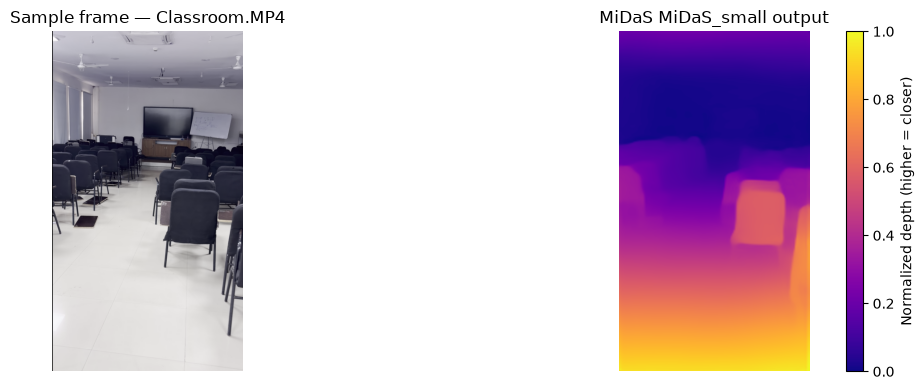

Depth map saved to: E:\EchoPath\Jetson_Implementation\output\midas_depth_calibration.png


In [17]:
# Workstation-only: calibration plots. matplotlib is not part of the device stack.
assert BACKEND == 'torch', 'Cell 5 is workstation-only (needs matplotlib)'

import matplotlib.pyplot as plt

SAMPLE_FRAME = 30
SAMPLE_VIDEO = VIDEO_JOBS[0][0]

cap = cv2.VideoCapture(SAMPLE_VIDEO)
for _ in range(SAMPLE_FRAME):
    ret, frame = cap.read()
    if not ret:
        break
cap.release()

# Apply rotation so calibration matches actual processing
rotation = get_video_rotation(SAMPLE_VIDEO)
frame = fix_rotation(frame, rotation)

# MiDaS inference
raw = estimate_depth_midas(frame)
norm = (raw - raw.min()) / (raw.max() - raw.min() + 1e-6)

print(f'Calibration frame from: {os.path.basename(SAMPLE_VIDEO)}')
print(f'Rotation applied: {rotation}°')
print()
print('MiDaS depth map stats (normalized 0-1):')
print(f'  min  = {norm.min():.3f}')
print(f'  max  = {norm.max():.3f}')
print(f'  mean = {norm.mean():.3f}')
print(f'  25th percentile = {np.percentile(norm, 25):.3f}')
print(f'  50th percentile = {np.percentile(norm, 50):.3f}')
print(f'  75th percentile = {np.percentile(norm, 75):.3f}')
print()
print('Recommended threshold starting points:')
print(f'  CLOSE_THRESH  ≈ {np.percentile(norm, 75):.2f}  (75th percentile)')
print(f'  MEDIUM_THRESH ≈ {np.percentile(norm, 50):.2f}  (50th percentile)')
print()
print('Update CLOSE_THRESH and MEDIUM_THRESH in Cell 4, then run Cell 7.')

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title(f'Sample frame — {os.path.basename(SAMPLE_VIDEO)}')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(norm, cmap='plasma')
plt.colorbar(label='Normalized depth (higher = closer)')
plt.title(f'MiDaS {MIDAS_MODEL_TYPE} output')
plt.axis('off')
plt.tight_layout()

calib_path = os.path.join(OUTPUT_DIR, 'midas_depth_calibration.png')
plt.savefig(calib_path, dpi=120)
plt.show()
print(f'Depth map saved to: {calib_path}')

## Cell 6 — Rotation diagnostic (run this once per dataset)

**What this does:** shows you what OpenCV delivers when reading a frame. Modern OpenCV (≥ 4.5) auto-rotates using video metadata; older versions don't. This cell tells you which case you're in.

**How to read the output:**
- Frame looks **right-side up** → leave `USE_OPENCV_AUTO_ROTATE = True` in Cell 7 ✓
- Frame looks **upside down or sideways** → set `USE_OPENCV_AUTO_ROTATE = False` in Cell 7


OpenCV orientation metadata : 90.0°
OpenCV auto-rotate enabled  : False
ffmpeg-reported rotation    : 90°
Frame shape as delivered    : (1080, 1920, 3)  (H, W, C)


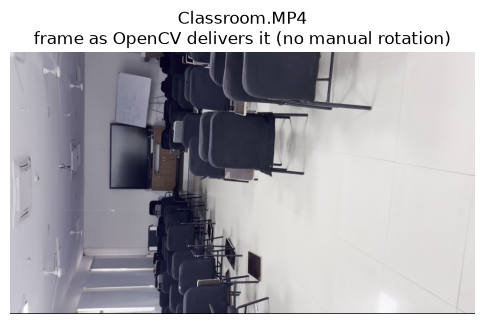


────────────────────────────────────────────────────────────
DECISION:
  If the image above is CORRECTLY oriented → Cell 7: USE_OPENCV_AUTO_ROTATE = True
  If the image above is ROTATED/UPSIDE-DOWN → Cell 7: USE_OPENCV_AUTO_ROTATE = False
────────────────────────────────────────────────────────────


In [18]:
test_video = VIDEO_JOBS[0][0]
cap = cv2.VideoCapture(test_video)

try:
    meta_rot = cap.get(cv2.CAP_PROP_ORIENTATION_META)
    auto = cap.get(cv2.CAP_PROP_ORIENTATION_AUTO)
    print(f'OpenCV orientation metadata : {meta_rot}°')
    print(f'OpenCV auto-rotate enabled  : {bool(auto)}')
except Exception as e:
    print(f'Orientation props unavailable: {e}')

ffmpeg_rot = get_video_rotation(test_video)
print(f'ffmpeg-reported rotation    : {ffmpeg_rot}°')

ret, frame = cap.read()
print(f'Frame shape as delivered    : {frame.shape}  (H, W, C)')
cap.release()

plt.figure(figsize=(6, 10))
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title(f'{os.path.basename(test_video)}\nframe as OpenCV delivers it (no manual rotation)')
plt.axis('off')
plt.show()

print()
print('─' * 60)
print('DECISION:')
print('  If the image above is CORRECTLY oriented → Cell 7: USE_OPENCV_AUTO_ROTATE = True')
print('  If the image above is ROTATED/UPSIDE-DOWN → Cell 7: USE_OPENCV_AUTO_ROTATE = False')
print('─' * 60)


## Cell 7 — Process video(s)

The alert-emission rule now comes from `AlertPolicy`, not from an ad-hoc
`if alert_txt != prev_alert` string comparison. That is what makes the log, the live
narration (cell 10) and the baked audio (cell 11) agree — previously all three used
different rules.

`alert_log` entries are now dicts with separate `label` / `proximity` / `direction`
fields instead of a concatenated string, which removes the fragile
`text.rsplit(' ', 2)` parsing downstream (it broke on any label containing a space).

Set `USE_OPENCV_AUTO_ROTATE` from what cell 6 showed you.

In [19]:
import subprocess

PROCESS_EVERY_N = 2

# ── ROTATION MODE ─────────────────────────────────────────────────────────
# True  = trust OpenCV's built-in rotation handling (modern OpenCV 4.5+).
# False = disable OpenCV auto-rotate and apply rotation manually from metadata.
# Set this based on what Cell 6 showed you.
USE_OPENCV_AUTO_ROTATE = True
# ──────────────────────────────────────────────────────────────────────────

all_jobs_log = {}
FFMPEG_EXE = imageio_ffmpeg.get_ffmpeg_exe()
print(f'Using ffmpeg: {FFMPEG_EXE}')
print(f'OpenCV auto-rotate: {USE_OPENCV_AUTO_ROTATE}\n')

for job_idx, (INPUT_VIDEO, OUTPUT_VIDEO) in enumerate(VIDEO_JOBS):
    vname = os.path.basename(INPUT_VIDEO)
    print(f'{"="*60}')
    print(f'[{job_idx+1}/{len(VIDEO_JOBS)}] Processing: {vname}')
    print(f'{"="*60}')

    cap = cv2.VideoCapture(INPUT_VIDEO)

    try:
        cap.set(cv2.CAP_PROP_ORIENTATION_AUTO, 1 if USE_OPENCV_AUTO_ROTATE else 0)
    except Exception:
        pass

    if USE_OPENCV_AUTO_ROTATE:
        manual_rotation = 0
    else:
        manual_rotation = get_video_rotation(INPUT_VIDEO)
    print(f'  Manual rotation to apply: {manual_rotation}°')

    # Probe one frame to get TRUE delivered dimensions after rotation
    ret, probe = cap.read()
    if not ret:
        print('  Could not read frame, skipping.')
        cap.release()
        continue
    probe = fix_rotation(probe, manual_rotation)
    out_h, out_w = probe.shape[:2]
    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

    fps   = cap.get(cv2.CAP_PROP_FPS)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    print(f'  Output size: {out_w}x{out_h} @ {fps:.1f} fps  |  {total} frames')

    tmp_out = os.path.splitext(OUTPUT_VIDEO)[0] + '_tmp' + os.path.splitext(OUTPUT_VIDEO)[1]
    writer  = cv2.VideoWriter(tmp_out, cv2.VideoWriter_fourcc(*'mp4v'),
                              fps, (out_w, out_h))

    frame_idx      = 0
    alert_log      = []
    last_annotated = None
    policy         = AlertPolicy()          # fresh timing state per video

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
        frame = fix_rotation(frame, manual_rotation)

        # Guard: if frame dimensions don't match writer dimensions
        # (can happen with some phone videos mid-stream), resize to match
        fh, fw = frame.shape[:2]
        if fw != out_w or fh != out_h:
            frame = cv2.resize(frame, (out_w, out_h))

        if frame_idx % PROCESS_EVERY_N == 0:
            annotated, alerts, _ = process_frame(frame)

            # Guard: ensure annotated frame matches writer dimensions
            # (prevents entire output going out of frame)
            if annotated.shape[1] != out_w or annotated.shape[0] != out_h:
                annotated = cv2.resize(annotated, (out_w, out_h))

            last_annotated = annotated

            chosen = policy.choose(alerts, frame_idx / float(fps))
            if chosen is not None:
                phrase = make_spoken_text(chosen['label'], chosen['proximity'],
                                          chosen['direction'])
                t_sec  = frame_idx / float(fps)
                print(f'  [Frame {frame_idx:>5} | {t_sec:6.2f}s] {phrase}')
                alert_log.append(dict(frame=frame_idx, t=round(t_sec, 3),
                                      label=chosen['label'],
                                      proximity=chosen['proximity'],
                                      direction=chosen['direction'],
                                      phrase=phrase))

            writer.write(annotated)
        else:
            writer.write(last_annotated if last_annotated is not None else frame)

        frame_idx += 1
        if frame_idx % 200 == 0:
            print(f'  {frame_idx}/{total} frames processed...')

    cap.release()
    writer.release()

    ffmpeg_result = subprocess.run(
        [FFMPEG_EXE, '-y',
         '-noautorotate',
         '-i', tmp_out,
         '-vcodec', 'libx264',
         '-crf', '23',
         '-metadata:s:v', 'rotate=0',
         OUTPUT_VIDEO],
        capture_output=True, text=True
    )
    if ffmpeg_result.returncode == 0:
        os.remove(tmp_out)
        print(f'  Saved (h264): {OUTPUT_VIDEO}')
    else:
        os.rename(tmp_out, OUTPUT_VIDEO)
        print(f'  ffmpeg error — saved raw: {OUTPUT_VIDEO}')
        print(ffmpeg_result.stderr[-300:])

    all_jobs_log[vname] = alert_log
    print(f'  Unique alerts: {len(alert_log)}\n')

print(f'{"="*60}')
print(f'All {len(VIDEO_JOBS)} videos done. Outputs in: {OUTPUT_DIR}')


Using ffmpeg: e:\EchoPath\Jetson_Implementation\env\Lib\site-packages\imageio_ffmpeg\binaries\ffmpeg-win-x86_64-v7.1.exe
OpenCV auto-rotate: True

[1/13] Processing: Classroom.MP4
  Manual rotation to apply: 0°
  Output size: 1080x1920 @ 30.0 fps  |  566 frames
  [Frame    52 |   1.73s] chair medium on your left
  [Frame   158 |   5.27s] chair medium ahead
  200/566 frames processed...
  [Frame   266 |   8.87s] chair close ahead
  [Frame   372 |  12.40s] chair medium on your right
  400/566 frames processed...
  [Frame   478 |  15.93s] chair close on your right
  Saved (h264): E:\EchoPath\Jetson_Implementation\output\echopath_Classroom.MP4
  Unique alerts: 5

[2/13] Processing: Enterance.MP4
  Manual rotation to apply: 0°
  Output size: 1080x1920 @ 30.0 fps  |  357 frames
  [Frame   186 |   6.20s] column medium ahead
  200/357 frames processed...
  [Frame   336 |  11.20s] stairs medium ahead
  Saved (h264): E:\EchoPath\Jetson_Implementation\output\echopath_Enterance.MP4
  Unique alerts

## Cell 8 — Video summary

In [20]:
for vname, log in all_jobs_log.items():
    print(f'\n── {vname} ({len(log)} alerts) ──')
    prev_t = None
    for a in log:
        gap = '' if prev_t is None else f'  (+{a["t"] - prev_t:.2f}s)'
        print(f'  [{a["t"]:6.2f}s | Frame {a["frame"]:>5}]  {a["phrase"]}{gap}')
        prev_t = a['t']

# ── verify the policy actually held ──────────────────────────────────────────
print('\n' + '=' * 62)
worst_any, worst_key = 1e9, 1e9
for vname, log in all_jobs_log.items():
    last_key = {}
    for a, b in zip(log, log[1:]):
        worst_any = min(worst_any, b['t'] - a['t'])
    for a in log:
        k = (a['label'], a['direction'])
        if k in last_key:
            worst_key = min(worst_key, a['t'] - last_key[k])
        last_key[k] = a['t']
total = sum(len(v) for v in all_jobs_log.values())
print(f'{total} alerts across {len(all_jobs_log)} videos')
if worst_any < 1e8:
    print(f'min gap, any two alerts      : {worst_any:.2f}s   (MIN_GAP_S = {MIN_GAP_S})')
    print(f'min gap, same label+direction: {worst_key:.2f}s   (cooldown  = {ALERT_COOLDOWN_S})')
    ok = worst_any >= MIN_GAP_S - 1e-6 and worst_key >= ALERT_COOLDOWN_S - 1e-6
    print('POLICY HELD' if ok else 'POLICY VIOLATED - investigate')


── Classroom.MP4 (5 alerts) ──
  [  1.73s | Frame    52]  chair medium on your left
  [  5.27s | Frame   158]  chair medium ahead  (+3.53s)
  [  8.87s | Frame   266]  chair close ahead  (+3.60s)
  [ 12.40s | Frame   372]  chair medium on your right  (+3.53s)
  [ 15.93s | Frame   478]  chair close on your right  (+3.53s)

── Enterance.MP4 (2 alerts) ──
  [  6.20s | Frame   186]  column medium ahead
  [ 11.20s | Frame   336]  stairs medium ahead  (+5.00s)

── FDW.mp4 (2 alerts) ──
  [  0.47s | Frame    14]  potted plant close on your right
  [  4.13s | Frame   124]  column close on your right  (+3.67s)

── Manthan.mp4 (4 alerts) ──
  [  2.13s | Frame    64]  table medium ahead
  [  6.73s | Frame   202]  table medium ahead  (+4.60s)
  [ 11.80s | Frame   354]  table close ahead  (+5.07s)
  [ 16.60s | Frame   498]  table close ahead  (+4.80s)

── Persons.mp4 (2 alerts) ──
  [  2.81s | Frame    84]  person close on your left
  [  7.35s | Frame   220]  person medium ahead  (+4.54s)

── Stair

## Cell 9 — Alert vocabulary + audio output  · **LIFTABLE**

### Why the sentences are pre-recorded

Speaking has two parts: **making** the voice, and **playing** it. Making a voice costs
real CPU; playing a file costs almost none.

The device can only ever say a fixed list of sentences —
`19 classes × {close, medium} × {left, ahead, right}` — so every one of them is
rendered **once here on the workstation** and the board just plays the matching file.
Same idea as a station announcement system: record in advance, press play at runtime.

### What this fixes

**1 · Urgent alerts can now interrupt.** `engine.runAndWait()` blocks until a phrase
finishes and cannot be stopped, so a `close` alert had to wait out a playing `medium`
one — about 2.4 s, long enough to walk into the thing being announced. A file is played
by a separate process, and a process can be killed mid-word.

**2 · Sound reaches the earphones.** The Eagle 101 has no headphone socket, so a USB
dongle is required. Nothing in the old code said *which* device to play through, so
ALSA would choose — often HDMI on a headless board. The result would be silence, with
no error anywhere. `ALSA_DEVICE` now makes it explicit.

**3 · The voice is the same on both machines.** `pyttsx3` drives SAPI5 on Windows and
espeak on Linux, which sound completely different — so the voice in your test videos
was not the voice the device would have had. Now both play the same rendered files.

`pyttsx3` is kept only as a fallback for phrases with no recording (`camera lost`,
`battery low`), and for rendering the vocabulary in the first place.

In [21]:
# ─── Cell 9: Alert vocabulary + audio output ────────────────────────────────
# LIFTABLE: stdlib only. AlertPolicy and make_spoken_text come from Cell 4.
import os
import subprocess
import threading
import time
import wave

PRIORITY = {'close': 0, 'medium': 1, 'far': 2}

EXTRA_PHRASES = {                      # spoken states with no (label, zone, dir) form
    'system_ready':     'echo path ready',
    'camera_lost':      'camera lost',
    'camera_restored':  'camera restored',
    'power_low':        'power low',
    'muted':            'muted',
    'unmuted':          'unmuted',
}


def vocab_key(label, proximity, direction):
    return '%s_%s_%s' % (label, proximity, direction)


def vocab_path(key):
    return os.path.join(VOCAB_DIR, key + '.wav')


def wav_seconds(path):
    w = wave.open(path)
    try:
        return w.getnframes() / float(w.getframerate())
    finally:
        w.close()


# ── rendering: workstation only ──────────────────────────────────────────────
def render_vocabulary(names=None, rate=SPEECH_RATE, volume=SPEECH_VOLUME, force=False):
    """Render every sentence the device can say. Skips files that already exist,
    so re-running is cheap. Takes a few minutes the first time."""
    import pyttsx3
    names = names or list(CLASS_NAMES)
    jobs = [(vocab_key(lab, prox, d), make_spoken_text(lab, prox, d))
            for lab in names for prox in ALERT_ZONES
            for d in ('left', 'ahead', 'right')]
    jobs += list(EXTRA_PHRASES.items())

    made, skipped = 0, 0
    for key, text in jobs:
        path = vocab_path(key)
        if os.path.exists(path) and not force:
            skipped += 1
            continue
        eng = pyttsx3.init()                    # fresh engine per phrase: more reliable
        eng.setProperty('rate', rate)
        eng.setProperty('volume', volume)
        eng.save_to_file(text, path)
        eng.runAndWait()
        try:
            eng.stop()
        except Exception:
            pass
        del eng
        time.sleep(0.05)
        made += 1
        if made % 20 == 0:
            print('  rendered %d/%d ...' % (made + skipped, len(jobs)))

    have = [f for f in os.listdir(VOCAB_DIR) if f.endswith('.wav')]
    mb = sum(os.path.getsize(os.path.join(VOCAB_DIR, f)) for f in have) / 1e6
    durs = [wav_seconds(os.path.join(VOCAB_DIR, f)) for f in have]
    print('vocabulary: %d phrases (%d new, %d already present), %.1f MB'
          % (len(have), made, skipped, mb))
    print('            durations %.2f-%.2fs, median %.2fs'
          % (min(durs), max(durs), sorted(durs)[len(durs) // 2]))
    if max(durs) > MIN_GAP_S:
        print('WARNING: longest phrase %.2fs exceeds MIN_GAP_S %.1fs - alerts would be '
              'dropped rather than spoken.' % (max(durs), MIN_GAP_S))
    return len(have)


# ── playback: one killable player, so speech can be interrupted ─────────────
class _Player(object):
    """Plays a WAV and can be stopped mid-word. aplay on Linux (the Jetson),
    winsound on Windows. Both are non-blocking so the worker can watch for a
    higher-priority alert while audio is running."""

    def __init__(self, alsa_device='default'):
        self.alsa_device = alsa_device
        self._proc = None          # linux
        self._ends_at = 0.0        # windows

    def play(self, path):
        if os.name == 'nt':
            import winsound
            winsound.PlaySound(path, winsound.SND_FILENAME | winsound.SND_ASYNC)
            self._ends_at = time.time() + wav_seconds(path)
        else:
            self._proc = subprocess.Popen(
                ['aplay', '-q', '-D', self.alsa_device, path],
                stdout=subprocess.PIPE, stderr=subprocess.PIPE)

    def is_playing(self):
        if os.name == 'nt':
            return time.time() < self._ends_at
        return self._proc is not None and self._proc.poll() is None

    def stop(self):
        if os.name == 'nt':
            import winsound
            winsound.PlaySound(None, winsound.SND_PURGE)
            self._ends_at = 0.0
        elif self._proc is not None and self._proc.poll() is None:
            self._proc.terminate()


class TTSSpeaker(object):
    """One pending slot, priority-ordered, and speech that can be cut off.

    The queue holds at most one alert, so overrun drops rather than accumulating lag.
    While a phrase is playing the worker keeps watching the slot: if something more
    urgent arrives, the current phrase is stopped mid-word.
    """

    def __init__(self, rate=SPEECH_RATE, volume=SPEECH_VOLUME, stale=STALE_S,
                 alsa_device=None, use_vocabulary=None):
        self._rate, self._volume, self._stale = rate, volume, stale
        self._use_vocab = USE_VOCABULARY if use_vocabulary is None else use_vocabulary
        self._player = _Player(ALSA_DEVICE if alsa_device is None else alsa_device)
        self._lock = threading.Lock()
        self._pending = None            # (priority, key, phrase, queued_at)
        self._stop = threading.Event()
        self._tts = None                # lazily built fallback engine
        self.spoken = 0
        self.dropped_stale = 0
        self.dropped_lower = 0
        self.preempted = 0
        self.fallback = 0
        self.thread = threading.Thread(target=self._run)
        self.thread.daemon = True
        self.thread.start()

    # -- fallback for anything with no recording --------------------------------
    def _speak_live(self, phrase):
        import pyttsx3
        if self._tts is None:
            self._tts = pyttsx3.init()
            self._tts.setProperty('rate', self._rate)
            self._tts.setProperty('volume', self._volume)
        self.fallback += 1
        self._tts.say(phrase)
        self._tts.runAndWait()          # cannot be interrupted - hence the vocabulary

    def _run(self):
        while not self._stop.is_set():
            with self._lock:
                item, self._pending = self._pending, None
            if item is None:
                time.sleep(0.03)
                continue
            priority, key, phrase, queued_at = item
            if time.time() - queued_at > self._stale:
                self.dropped_stale += 1          # describes where the user WAS
                continue

            path = vocab_path(key) if key else None
            if self._use_vocab and path and os.path.exists(path):
                try:
                    self._player.play(path)
                    self.spoken += 1
                    while self._player.is_playing() and not self._stop.is_set():
                        with self._lock:
                            waiting = self._pending
                        if waiting is not None and waiting[0] < priority:
                            self._player.stop()   # cut off for something more urgent
                            self.preempted += 1
                            break
                        time.sleep(0.02)
                except Exception as e:
                    print('[audio] %s' % e)
                    self._speak_live(phrase)
            else:
                self._speak_live(phrase)
                self.spoken += 1

    def say(self, label, proximity, direction):
        """Queue an alert. Returns True if accepted, False if dropped."""
        priority = PRIORITY.get(proximity, 9)
        with self._lock:
            if self._pending is not None and priority >= self._pending[0]:
                self.dropped_lower += 1
                return False
            self._pending = (priority, vocab_key(label, proximity, direction),
                             make_spoken_text(label, proximity, direction), time.time())
        return True

    def announce(self, key):
        """Speak a non-alert state such as 'system_ready'. Lowest priority."""
        with self._lock:
            self._pending = (2, key, EXTRA_PHRASES.get(key, key.replace('_', ' ')),
                             time.time())

    def stats(self):
        return {'spoken': self.spoken, 'preempted': self.preempted,
                'dropped_stale': self.dropped_stale,
                'dropped_lower_priority': self.dropped_lower,
                'live_synthesis_fallback': self.fallback}

    def stop(self):
        self._stop.set()
        self._player.stop()
        self.thread.join(timeout=2)


# ── render the vocabulary, then check speech fits inside the alert gap ───────
_n = render_vocabulary()

_t = TTSSpeaker()
_t.say('chair', 'medium', 'left')       # starts playing
time.sleep(0.4)
_t.say('column', 'close', 'ahead')      # more urgent -> should cut the chair off
time.sleep(5)
print('audio check:', _t.stats())
print('expected: spoken=2, preempted=1, live_synthesis_fallback=0')
_t.stop()

vocabulary: 121 phrases (0 new, 120 already present), 12.5 MB
            durations 1.29-3.18s, median 2.36s
audio check: {'spoken': 2, 'preempted': 1, 'dropped_stale': 0, 'dropped_lower_priority': 0, 'live_synthesis_fallback': 0}
expected: spoken=2, preempted=1, live_synthesis_fallback=0


## Cell 10 — Narrate a processed video with voice alerts

Uses the same `TTSSpeaker`, so what you hear here is what the live device would do:
one alert at a time, closer alerts replacing waiting ones, stale alerts discarded
rather than spoken late.

The counters printed at the end (`spoken` / `dropped_stale` / `dropped_lower_priority`)
tell you whether the policy is well-tuned. Lots of drops means alerts are being
generated faster than they can be spoken — raise `MIN_GAP_S`, or shorten the phrasing.

In [22]:
# ─── Cell 10: Play alerts from a processed video with voice ─────────────────
import time

VIDEO_TO_NARRATE = None      # filename from VIDEO_JOBS, or None for the first
SHOW_VIDEO       = True      # False = audio only

if not all_jobs_log:
    print('No processed videos found. Run Cell 7 first.')
else:
    vname = VIDEO_TO_NARRATE or next(iter(all_jobs_log))
    if vname not in all_jobs_log:
        print(f"'{vname}' not processed. Available: {list(all_jobs_log)}")
    else:
        alert_log = all_jobs_log[vname]
        output_path = None
        for inp, out in VIDEO_JOBS:
            if os.path.basename(inp) == vname:
                output_path = out
                break

        cap_tmp = cv2.VideoCapture(os.path.join(VIDEO_DIR, vname))
        fps = cap_tmp.get(cv2.CAP_PROP_FPS) or 30.0
        cap_tmp.release()

        print(f'Narrating: {vname}   ({len(alert_log)} alerts, {fps:.1f} fps)')
        speaker  = TTSSpeaker()
        idx      = 0
        start    = time.time()

        if SHOW_VIDEO and output_path and os.path.exists(output_path):
            cap = cv2.VideoCapture(output_path)
            frame_idx = 0
            while cap.isOpened():
                ret, frame = cap.read()
                if not ret:
                    break
                while idx < len(alert_log) and alert_log[idx]['frame'] <= frame_idx:
                    a = alert_log[idx]
                    ok = speaker.say(a['label'], a['proximity'], a['direction'])
                    print(f'  [{a["t"]:6.2f}s] {"speak" if ok else "drop "} {a["phrase"]}')
                    idx += 1
                cv2.imshow('EchoPath narration (q to quit)', frame)
                target = start + frame_idx / fps
                delay  = target - time.time()
                if delay > 0:
                    time.sleep(delay)
                if cv2.waitKey(1) & 0xFF == ord('q'):
                    break
                frame_idx += 1
            cap.release()
            cv2.destroyAllWindows()
        else:
            for a in alert_log:
                delay = start + a['t'] - time.time()
                if delay > 0:
                    time.sleep(delay)
                ok = speaker.say(a['label'], a['proximity'], a['direction'])
                print(f'  [{a["t"]:6.2f}s] {"speak" if ok else "drop "} {a["phrase"]}')

        time.sleep(3)
        speaker.stop()
        print('\nNarration complete.', speaker.stats())

Narrating: Classroom.MP4   (5 alerts, 30.0 fps)
  [  1.73s] speak chair medium on your left
  [  5.27s] speak chair medium ahead
  [  8.87s] speak chair close ahead
  [ 12.40s] speak chair medium on your right
  [ 15.93s] speak chair close on your right

Narration complete. {'spoken': 5, 'preempted': 0, 'dropped_stale': 0, 'dropped_lower_priority': 0, 'live_synthesis_fallback': 0}


## Cell 11 — Bake voice alerts into the output videos

Writes `echopath_<name>_voiced.mp4` alongside each processed video, into
`Jetson_Implementation/output/`.

Two changes from the original:

**`smooth_alerts()` is gone.** It applied a *third* spacing rule (`MIN_GAP_SECONDS =
2.0`) on top of the two in cell 9, so the video never matched what the live device
would say. Cell 7 already spaced the log correctly via `AlertPolicy`; re-filtering here
would only disagree with it.

**Clips are serialised, not just delayed.** `adelay` + `amix` places each clip at its
raw timestamp and overlays anything that collides — and phrases run up to 3.2 s. Each
clip now starts at `max(its timestamp, end of the previous clip)`, which both removes
the overlap and matches `TTSSpeaker`'s one-at-a-time behaviour. Any clip that would
run past the end of the video is dropped.

In [23]:
# ─── Cell 11: Bake voice alerts INTO the saved videos ───────────────────────
import subprocess
import tempfile
import wave
from pathlib import Path
import pyttsx3

FFMPEG_EXE    = imageio_ffmpeg.get_ffmpeg_exe()
VOICED_SUFFIX = '_voiced'


def render_alert_wav(phrase, out_path, rate=SPEECH_RATE, volume=SPEECH_VOLUME):
    """Render one phrase to WAV. Fresh engine each call - more reliable on SAPI5."""
    engine = pyttsx3.init()
    engine.setProperty('rate', rate)
    engine.setProperty('volume', volume)
    engine.save_to_file(phrase, str(out_path))
    engine.runAndWait()
    try:
        engine.stop()
    except Exception:
        pass
    del engine
    time.sleep(0.05)


def wav_seconds(path):
    w = wave.open(str(path))
    try:
        return w.getnframes() / float(w.getframerate())
    finally:
        w.close()


def bake_voice_into_video(input_video, output_video, alert_log, fps, total_frames):
    """Render each alert to WAV, then mux them in SERIALISED so they never overlap."""
    if not alert_log:
        import shutil
        shutil.copy(input_video, output_video)
        print('  no alerts - copied video unchanged')
        return True

    duration = total_frames / fps if fps > 0 else 0.0

    with tempfile.TemporaryDirectory() as tmp:
        tmp = Path(tmp)

        # one WAV per unique phrase
        wavs = {}
        for a in alert_log:
            if a['phrase'] not in wavs:
                w = tmp / ('clip_%04d.wav' % len(wavs))
                render_alert_wav(a['phrase'], w)
                if not w.exists() or w.stat().st_size < 500:
                    print('  TTS produced nothing for: "%s"' % a['phrase'])
                    return False
                wavs[a['phrase']] = w

        # serialise: a clip never starts before the previous one has finished
        clips, cursor, pushed, dropped = [], 0.0, 0, 0
        for a in alert_log:
            w = wavs[a['phrase']]
            dur = wav_seconds(w)
            start = max(a['t'], cursor)
            if start + dur > duration:
                dropped += 1
                continue
            if start > a['t'] + 0.01:
                pushed += 1
            clips.append((int(start * 1000), w))
            cursor = start + dur
        if pushed or dropped:
            print('  %d clip(s) delayed to avoid overlap, %d dropped past end'
                  % (pushed, dropped))
        if not clips:
            import shutil
            shutil.copy(input_video, output_video)
            return True

        uniq = sorted(set(str(w) for _, w in clips))
        cmd = [FFMPEG_EXE, '-y', '-i', str(input_video)]
        for w in uniq:
            cmd += ['-i', w]

        parts, labels = [], []
        for i, (delay_ms, w) in enumerate(clips):
            src = uniq.index(str(w)) + 1            # +1: video is input 0
            parts.append('[%d:a]aresample=44100,adelay=%d|%d[d%d]'
                         % (src, delay_ms, delay_ms, i))
            labels.append('[d%d]' % i)
        if len(clips) == 1:
            parts.append('[d0]apad[aout]')
        else:
            parts.append('%samix=inputs=%d:normalize=0[m]' % (''.join(labels), len(clips)))
            parts.append('[m]apad[aout]')

        cmd += ['-filter_complex', ';'.join(parts),
                '-map', '0:v', '-map', '[aout]',
                '-c:v', 'copy', '-c:a', 'aac', '-b:a', '128k', '-ar', '44100',
                '-t', '%.3f' % duration, str(output_video)]

        r = subprocess.run(cmd, capture_output=True, text=True)
        if r.returncode != 0:
            print('  ffmpeg failed:\n' + r.stderr[-600:])
            return False
        return True


print('Baking voice alerts (spacing already enforced by AlertPolicy in Cell 7)\n')
if not all_jobs_log:
    print('No processed videos found. Run Cell 7 first.')
else:
    for vname, alert_log in all_jobs_log.items():
        print(f'━━━ {vname} ━━━')
        processed = None
        for inp, out in VIDEO_JOBS:
            if os.path.basename(inp) == vname:
                processed = out
                break
        if not processed or not os.path.exists(processed):
            print('  processed video not found, skipping\n')
            continue

        cap = cv2.VideoCapture(processed)
        fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        cap.release()

        base, ext = os.path.splitext(processed)
        voiced = base + VOICED_SUFFIX + ext
        print(f'  {len(alert_log)} alerts')
        if bake_voice_into_video(processed, voiced, alert_log, fps, total_frames):
            print(f'  saved: {voiced}\n')
        else:
            print(f'  FAILED on {vname}\n')

print('Done. Outputs in:', OUTPUT_DIR)

Baking voice alerts (spacing already enforced by AlertPolicy in Cell 7)

━━━ Classroom.MP4 ━━━
  5 alerts
  saved: E:\EchoPath\Jetson_Implementation\output\echopath_Classroom_voiced.MP4

━━━ Enterance.MP4 ━━━
  2 alerts
  0 clip(s) delayed to avoid overlap, 1 dropped past end
  saved: E:\EchoPath\Jetson_Implementation\output\echopath_Enterance_voiced.MP4

━━━ FDW.mp4 ━━━
  2 alerts
  saved: E:\EchoPath\Jetson_Implementation\output\echopath_FDW_voiced.mp4

━━━ Manthan.mp4 ━━━
  4 alerts
  0 clip(s) delayed to avoid overlap, 1 dropped past end
  saved: E:\EchoPath\Jetson_Implementation\output\echopath_Manthan_voiced.mp4

━━━ Persons.mp4 ━━━
  2 alerts
  saved: E:\EchoPath\Jetson_Implementation\output\echopath_Persons_voiced.mp4

━━━ Stairs.MP4 ━━━
  3 alerts
  0 clip(s) delayed to avoid overlap, 1 dropped past end
  saved: E:\EchoPath\Jetson_Implementation\output\echopath_Stairs_voiced.MP4

━━━ Water.mp4 ━━━
  2 alerts
  saved: E:\EchoPath\Jetson_Implementation\output\echopath_Water_voic

## Cell 12 — Live camera runtime (Jetson)  · **LIFTABLE**

**This is what actually runs on the board.** Everything above it either loads models or
processes recorded files; this is the only cell that reads the CSI camera and speaks in
real time.

Cells 5–11 are **workstation-only** — they need `matplotlib`, video files, or ffmpeg,
none of which belong on the device.

The camera goes through `nvarguscamerasrc`, not a USB webcam. The Eagle 101's MIPI CSI-2
connectors feed the Tegra ISP, which does debayer, white balance and format conversion
in dedicated silicon and hands the frame over without a copy. A USB webcam would instead
send MJPEG that the four A57 cores have to JPEG-decode 30 times a second — roughly a
third of a core, permanently, on a board where you are already short of CPU.

```bash
# on the Jetson
python3 -m venv --system-site-packages ~/echopath-env
source ~/echopath-env/bin/activate
pip install pycuda            # tensorrt, cv2 and numpy come from JetPack
# do NOT pip install opencv-python: it shadows JetPack's GStreamer build and the
# CSI pipeline silently stops opening
```

In [24]:
# ─── Cell 12: Live camera runtime (Jetson) ──────────────────────────────────
# LIFTABLE. Reads the CSI camera, runs the same process_frame() as the file path,
# applies the same AlertPolicy, speaks through the same TTSSpeaker.
import time


def csi_pipeline(sensor_id=None, w=None, h=None, fps=None, flip=None):
    """GStreamer pipeline for a MIPI CSI-2 camera via the Tegra ISP."""
    return ('nvarguscamerasrc sensor-id=%d ! '
            'video/x-raw(memory:NVMM),width=%d,height=%d,framerate=%d/1 ! '
            'nvvidconv flip-method=%d ! video/x-raw,format=BGRx ! '
            'videoconvert ! video/x-raw,format=BGR ! '
            'appsink drop=1 max-buffers=1'
            % (CSI_SENSOR_ID if sensor_id is None else sensor_id,
               CSI_W if w is None else w,
               CSI_H if h is None else h,
               CSI_FPS if fps is None else fps,
               CSI_FLIP if flip is None else flip))


def open_camera():
    """CSI on the Jetson, plain webcam index 0 on the workstation (for dry runs)."""
    if BACKEND == 'tensorrt':
        cap = cv2.VideoCapture(csi_pipeline(), cv2.CAP_GSTREAMER)
        if not cap.isOpened():
            raise RuntimeError(
                'CSI camera did not open. Check: (1) the vendor BSP device tree is '
                'flashed, (2) cv2.getBuildInformation() reports GStreamer YES, '
                '(3) the pipeline works standalone with gst-launch-1.0.')
        return cap
    cap = cv2.VideoCapture(0, cv2.CAP_DSHOW if os.name == 'nt' else 0)
    if not cap.isOpened():
        raise RuntimeError('no camera at index 0')
    cap.set(cv2.CAP_PROP_FRAME_WIDTH, CSI_W)
    cap.set(cv2.CAP_PROP_FRAME_HEIGHT, CSI_H)
    return cap


def run_live(max_seconds=None, speak=True, show=False, depth_every_n=3):
    """Live loop. depth_every_n>1 because depth changes far more slowly than
    object identity, and MiDaS costs about twice what YOLO does."""
    cap      = open_camera()
    policy   = AlertPolicy()
    speaker  = TTSSpeaker() if speak else None
    t0       = time.time()
    frames   = 0
    spoken   = 0
    depth    = None

    if speaker is not None:
        speaker.announce('system_ready')             # the only way a blind user knows
                                                     # the device has finished booting

    print('running - Ctrl-C (or q in the window) to stop')
    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                print('camera returned no frame'); break

            if frames % depth_every_n == 0:
                depth = estimate_depth_midas(frame)

            annotated, alerts, _ = process_frame(frame) if show else (None, None, None)
            if not show:
                # decision path only - no annotation, which costs real CPU on ARM
                results = yolo_model.predict(frame, conf=CONF_THRESH, verbose=False)[0]
                h, w = frame.shape[:2]
                d_min, d_max = depth.min(), depth.max()
                dmap = (depth - d_min) / (d_max - d_min + 1e-6)
                detections = []
                for box in results.boxes:
                    bbox  = box.xyxy[0].cpu().numpy()
                    label = yolo_model.names[int(box.cls[0])]
                    avg_depth, proximity, direction = get_depth_and_zone(dmap, bbox, w, h)
                    detections.append(dict(label=label, bbox=bbox,
                                           conf=float(box.conf[0]), depth=avg_depth,
                                           proximity=proximity, direction=direction))
                alerts = generate_alerts(detections)

            chosen = policy.choose(alerts, time.time() - t0)
            if chosen is not None:
                phrase = make_spoken_text(chosen['label'], chosen['proximity'],
                                          chosen['direction'])
                print('  [%6.2fs] %s' % (time.time() - t0, phrase))
                spoken += 1
                if speaker is not None:
                    speaker.say(chosen['label'], chosen['proximity'], chosen['direction'])

            if show and annotated is not None:
                cv2.imshow('EchoPath (q to quit)', annotated)
                if cv2.waitKey(1) & 0xFF == ord('q'):
                    break

            frames += 1
            if max_seconds and (time.time() - t0) > max_seconds:
                break
    except KeyboardInterrupt:
        print('\ninterrupted')
    finally:
        cap.release()
        if show:
            cv2.destroyAllWindows()
        if speaker is not None:
            time.sleep(1.5)
            print('speaker stats:', speaker.stats())
            speaker.stop()

    el = time.time() - t0
    print('%d frames in %.1fs = %.1f FPS | %d alerts'
          % (frames, el, frames / max(el, 1e-6), spoken))


# Guarded so a stray "Run All" on the workstation does not open your laptop camera.
RUN_LIVE = False
if RUN_LIVE:
    run_live(max_seconds=60, speak=True, show=(BACKEND == 'torch'))
else:
    print('set RUN_LIVE = True to start the live camera loop')
    print('camera pipeline:')
    print(' ', csi_pipeline() if BACKEND == 'tensorrt' else 'cv2.VideoCapture(0)')

set RUN_LIVE = True to start the live camera loop
camera pipeline:
  cv2.VideoCapture(0)
